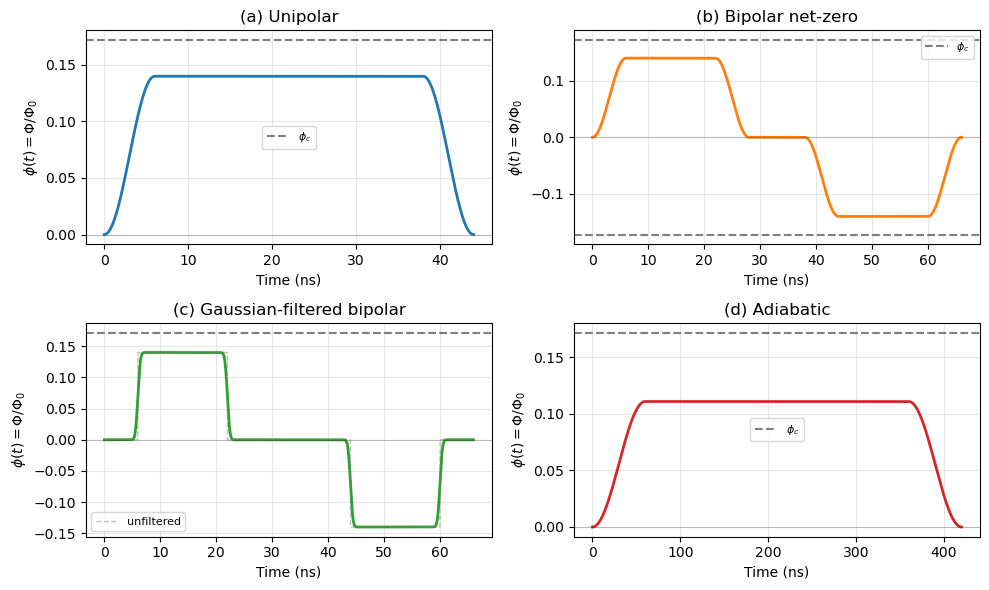

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()

#shared parameters
phi_hold = 0.14
t_rise = 6.0
t_hold = 32.0
t_idle = 10.0
phi_c = 0.172

#Unipolar
T = 2*t_rise + t_hold
t = np.linspace(0, T, 1000)
phi = np.zeros_like(t)
for i, ti in enumerate(t):
    if ti < t_rise:
        phi[i] = phi_hold * np.sin(np.pi*ti/(2*t_rise))**2
    elif ti < t_rise + t_hold:
        phi[i] = phi_hold
    else:
        phi[i] = phi_hold * (1 - np.sin(np.pi*(ti-t_rise-t_hold)/(2*t_rise))**2)
axes[0].plot(t, phi, lw=2, color='C0')
axes[0].axhline(phi_c, color='k', ls='--', alpha=0.5, label=r'$\phi_c$')
axes[0].set_title('(a) Unipolar')

#Bipolar
t3 = 2*t_rise + t_hold/2 + t_idle
T2 = 4*t_rise + t_hold + t_idle
t = np.linspace(0, T2, 2000)
phi = np.zeros_like(t)
for i, ti in enumerate(t):
    if ti < t_rise:
        phi[i] = phi_hold * np.sin(np.pi*ti/(2*t_rise))**2
    elif ti < t_rise + t_hold/2:
        phi[i] = phi_hold
    elif ti < 2*t_rise + t_hold/2:
        phi[i] = phi_hold*(1 - np.sin(np.pi*(ti-t_rise-t_hold/2)/(2*t_rise))**2)
    elif ti < t3:
        phi[i] = 0
    elif ti < t3 + t_rise:
        phi[i] = -phi_hold * np.sin(np.pi*(ti-t3)/(2*t_rise))**2
    elif ti < t3 + t_rise + t_hold/2:
        phi[i] = -phi_hold
    else:
        phi[i] = -phi_hold*(1 - np.sin(np.pi*(ti-t3-t_rise-t_hold/2)/(2*t_rise))**2)
axes[1].plot(t, phi, lw=2, color='C1')
axes[1].axhline(phi_c, color='k', ls='--', alpha=0.5, label=r'$\phi_c$')
axes[1].axhline(-phi_c, color='k', ls='--', alpha=0.5)
axes[1].set_title('(b) Bipolar net-zero')

#Gaussian-filtered
dt = 0.02
t_gf = np.arange(0, T2, dt)
phi_rect = np.zeros_like(t_gf)
for i, ti in enumerate(t_gf):
    if t_rise <= ti < t_rise + t_hold/2:
        phi_rect[i] = phi_hold
    elif t3 + t_rise <= ti < t3 + t_rise + t_hold/2:
        phi_rect[i] = -phi_hold
sigma_samples = 0.35 / dt
phi_filt = gaussian_filter1d(phi_rect, sigma=sigma_samples)
axes[2].plot(t_gf, phi_filt, lw=2, color='C2')
axes[2].plot(t_gf, phi_rect, lw=1, ls='--', color='gray', alpha=0.5, label='unfiltered')
axes[2].axhline(phi_c, color='k', ls='--', alpha=0.5)
axes[2].set_title('(c) Gaussian-filtered bipolar')
axes[2].legend(fontsize=8)

#Adiabatic
t_rise_ad = 60.0
phi_hold_ad = 0.111
t_hold_ad = 300.0
T_ad = 2*t_rise_ad + t_hold_ad
t = np.linspace(0, T_ad, 2000)
phi = np.zeros_like(t)
for i, ti in enumerate(t):
    if ti < t_rise_ad:
        phi[i] = phi_hold_ad * np.sin(np.pi*ti/(2*t_rise_ad))**2
    elif ti < t_rise_ad + t_hold_ad:
        phi[i] = phi_hold_ad
    else:
        phi[i] = phi_hold_ad*(1 - np.sin(np.pi*(ti-t_rise_ad-t_hold_ad)/(2*t_rise_ad))**2)
axes[3].plot(t, phi, lw=2, color='C3')
axes[3].axhline(phi_c, color='k', ls='--', alpha=0.5, label=r'$\phi_c$')
axes[3].set_title('(d) Adiabatic')

for ax in axes:
    ax.set_xlabel('Time (ns)')
    ax.set_ylabel(r'$\phi(t) = \Phi/\Phi_0$')
    ax.axhline(0, color='k', alpha=0.2, lw=0.8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
#plt.savefig('fig_pulse_shapes.pdf', dpi=150)
plt.show()